In [2]:
import pandas as pd

df = pd.read_csv("cpcb-aqi.csv.gz")
hrs = [c for c in df.columns if ":" in c]
df[hrs] = df[hrs].apply(pd.to_numeric, errors="coerce")
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df = df.dropna(subset=["Date"])

out = pd.DataFrame({
    "station_id": df["Station ID"],
    "state": df["State"].str.strip(),
    "city": df["City"].str.strip(),
    "station_name": df["Station Name"].str.strip(),
    "aqi_date": df["Date"].dt.strftime("%Y-%m-%d"),
    "avg_aqi": df[hrs].mean(axis=1).round(1),
    "max_aqi": df[hrs].max(axis=1),
    "hours_recorded": df[hrs].notna().sum(axis=1),
})
out = out[out.hours_recorded >= 12].copy()
out["year"] = pd.to_datetime(out.aqi_date).dt.year
out["month"] = pd.to_datetime(out.aqi_date).dt.month
out = out.drop_duplicates(["station_id", "aqi_date"])
out.to_csv("aqi_daily_clean.csv", index=False)
print(out.shape)

(269091, 10)


In [3]:
out.head()

,station_id,state,city,station_name,aqi_date,avg_aqi,max_aqi,hours_recorded,year,month
1,site_1406,Andhra Pradesh,Amaravati,Secretariat Amaravati APPCB,2017-12-12,206.3,315.0,24,2017,12
2,site_1406,Andhra Pradesh,Amaravati,Secretariat Amaravati APPCB,2017-12-13,128.1,216.0,24,2017,12
3,site_1406,Andhra Pradesh,Amaravati,Secretariat Amaravati APPCB,2017-12-14,134.7,197.0,24,2017,12
4,site_1406,Andhra Pradesh,Amaravati,Secretariat Amaravati APPCB,2017-12-15,150.8,243.0,23,2017,12
5,site_1406,Andhra Pradesh,Amaravati,Secretariat Amaravati APPCB,2017-12-16,177.4,255.0,24,2017,12


In [4]:
out.tail()

,station_id,state,city,station_name,aqi_date,avg_aqi,max_aqi,hours_recorded,year,month
562873,site_1419,West Bengal,Siliguri,Ward-32 Bapupara Siliguri WBPCB,2023-12-27,97.8,188.0,24,2023,12
562874,site_1419,West Bengal,Siliguri,Ward-32 Bapupara Siliguri WBPCB,2023-12-28,86.7,168.0,24,2023,12
562875,site_1419,West Bengal,Siliguri,Ward-32 Bapupara Siliguri WBPCB,2023-12-29,101.1,210.0,24,2023,12
562876,site_1419,West Bengal,Siliguri,Ward-32 Bapupara Siliguri WBPCB,2023-12-30,101.4,211.0,24,2023,12
562877,site_1419,West Bengal,Siliguri,Ward-32 Bapupara Siliguri WBPCB,2023-12-31,87.8,135.0,24,2023,12


In [5]:
out.duplicated()

1         False
2         False
3         False
4         False
5         False
          ...  
562873    False
562874    False
562875    False
562876    False
562877    False
Length: 269091, dtype: bool

In [10]:
out["city"].nunique()
out["state"].unique()
out["year"].value_counts().sort_index()      # rows per year
out["city"].value_counts().head(10)          # cities with most data

city
Delhi        2539
Bengaluru    2534
Mumbai       2512
Hyderabad    2435
Faridabad    2404
Gurugram     2397
Jodhpur      2389
Noida        2374
Ghaziabad    2369
Varanasi     2356
Name: count, dtype: int64

In [6]:
out.isnull().sum()

station_id        0
state             0
city              0
station_name      0
aqi_date          0
avg_aqi           0
max_aqi           0
hours_recorded    0
year              0
month             0
dtype: int64

In [7]:
out["year"].value_counts().sort_index()

year
2017     5926
2018    20498
2019    31597
2020    38630
2021    44548
2022    53789
2023    74103
Name: count, dtype: int64

In [8]:
out["city"].value_counts().head(10)

city
Delhi        2539
Bengaluru    2534
Mumbai       2512
Hyderabad    2435
Faridabad    2404
Gurugram     2397
Jodhpur      2389
Noida        2374
Ghaziabad    2369
Varanasi     2356
Name: count, dtype: int64

In [9]:
cnt = out.groupby(["city", "year"]).size().unstack(fill_value=0)
core_cities = cnt[(cnt >= 150).all(axis=1)].index
core = out[out["city"].isin(core_cities)].copy()
print(len(core_cities), core.shape)

18 (42672, 10)


In [10]:
core.groupby("city")["avg_aqi"].mean().round(1).sort_values(ascending=False)   # city ranking
core.groupby("year")["avg_aqi"].mean().round(1)                                 # yearly trend
core.groupby("month")["avg_aqi"].mean().round(1)                                # seasonality

month
1     224.3
2     190.4
3     159.2
4     149.7
5     138.3
6     118.4
7      81.9
8      80.5
9      86.7
10    162.6
11    229.7
12    236.9
Name: avg_aqi, dtype: float64

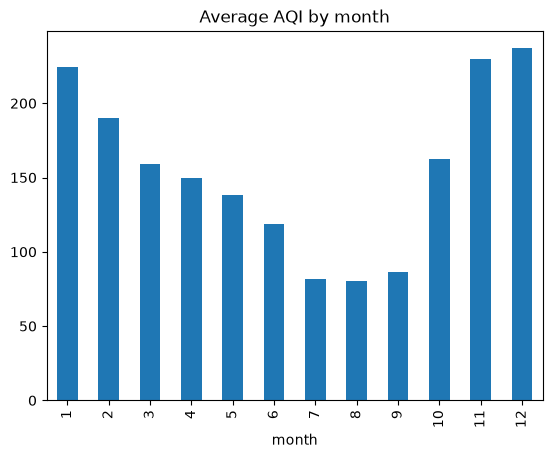

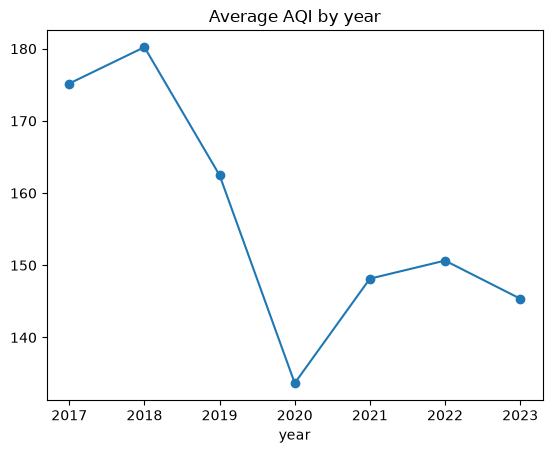

In [17]:
import matplotlib.pyplot as plt

core.groupby("month")["avg_aqi"].mean().plot(kind="bar", title="Average AQI by month")
plt.show()

core.groupby("year")["avg_aqi"].mean().plot(marker="o", title="Average AQI by year")
plt.show()

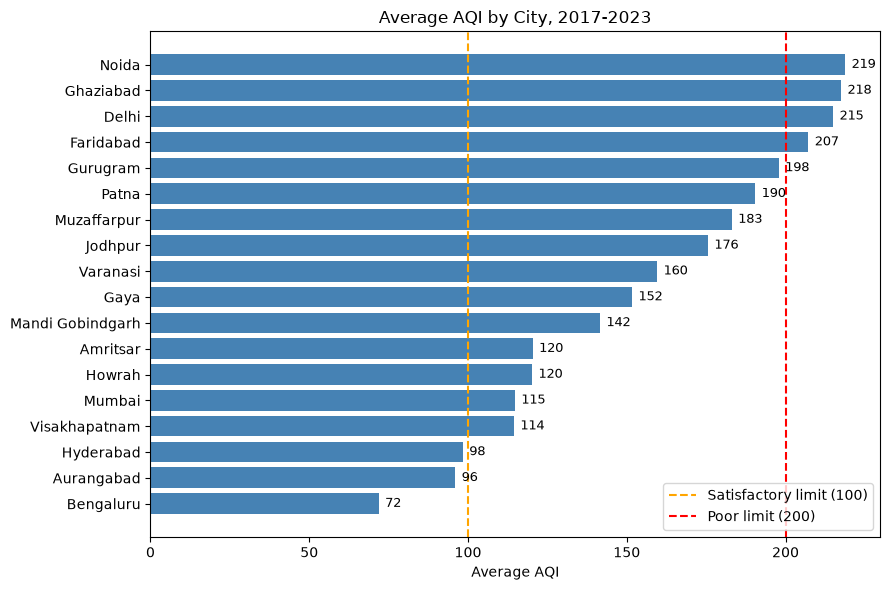

In [19]:
import matplotlib.pyplot as plt

city_aqi = core.groupby("city")["avg_aqi"].mean().round(1).sort_values()

plt.figure(figsize=(9, 6))
bars = plt.barh(city_aqi.index, city_aqi.values, color="steelblue")
plt.axvline(100, color="orange", linestyle="--", label="Satisfactory limit (100)")
plt.axvline(200, color="red", linestyle="--", label="Poor limit (200)")
plt.title("Average AQI by City, 2017-2023")
plt.xlabel("Average AQI")
plt.legend()
for bar in bars:
    plt.text(bar.get_width() + 2, bar.get_y() + bar.get_height()/2,
             f"{bar.get_width():.0f}", va="center", fontsize=9)
plt.tight_layout()
plt.show()

In [20]:
import os
print(os.getcwd())

C:\Users\user


In [25]:
import os
df.to_csv("aqi_daily_clean.csv", index=False)
print(os.getcwd())

C:\Users\user


In [26]:
from pathlib import Path

home = Path.home()
for p in [home / "Desktop", home / "OneDrive" / "Desktop", home / "OneDrive - Personal" / "Desktop"]:
    print(p, "->", p.exists())

C:\Users\user\Desktop -> False
C:\Users\user\OneDrive\Desktop -> True
C:\Users\user\OneDrive - Personal\Desktop -> False


In [27]:
from pathlib import Path

home = Path.home()
path = home / "OneDrive" / "Desktop" / "aqi_daily_clean.csv"
df.to_csv(path, index=False)
print("Saved to:", path)

Saved to: C:\Users\user\OneDrive\Desktop\aqi_daily_clean.csv


In [28]:
print(path.exists())

True
